# Real-to-synthetic overdraft detection

This notebook trains a **supervised rare-event classifier** on real Berka transactions and evaluates the unchanged model on held-out real data and ClavaDDPM synthetic transactions. It is an overdraft detector, not an unsupervised anomaly-scoring model.

## Target selection

The candidate analysis favors `trans.balance < 0` for this task: it is a direct indicator of an account solvency breach and is available for transaction-level evaluation at scale. `loan.status` is an explicit severe-debt outcome, but describes only 682 loan contracts and is not the transaction overdraft target. The target is `overdraft = (balance < 0)`.

`balance` is used **only** to construct the label and is excluded from all predictors. Transaction/account IDs are also excluded. The predictor set is `trans_date`, `trans_type`, `operation`, `amount`, `k_symbol`, and `bank`; the beneficiary `account` field is excluded because it is an account identifier rather than a generalizable transaction attribute.

The full raw real transaction file is used here (1,056,320 rows in the bundled data); the preprocessed ClavaDDPM input is a 20,000-row sample. The generated synthetic table is evaluated using its own `balance < 0` labels. Metrics on synthetic data measure how well a detector trained on real data transfers to the generated distribution; they are not, on their own, proof that the synthetic table is realistic or that an individual prediction is correct.

In [1]:
import os
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


SEED = 42
TARGET = "overdraft"
NUMERIC_FEATURES = ["trans_date", "amount"]
CATEGORICAL_FEATURES = ["trans_type", "operation", "k_symbol", "bank"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from the current directory or notebook path."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml in the current directory or its parents.")

ROOT = find_project_root()
BERKA_DIR = ROOT / "implementations/tabular_data/multi_table/data/berka"
RAW_TRANS_PATH = BERKA_DIR / "raw_data/trans.csv"
ENCODERS_PATH = BERKA_DIR / "label_encoders.pkl"
SYNTHETIC_TRANS_PATH = (
    ROOT
    / "implementations/tabular_data/multi_table/results/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv"
)

for path in (RAW_TRANS_PATH, ENCODERS_PATH, SYNTHETIC_TRANS_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset/preprocessing artifact not found: {path}")

os.chdir(ROOT)
print(f"Project root: {ROOT}")
print(f"Real transactions: {RAW_TRANS_PATH}")
print(f"Synthetic transactions: {SYNTHETIC_TRANS_PATH}")

Project root: /home/coder/synthetic-data-bootcamp
Real transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka/raw_data/trans.csv
Synthetic transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/results/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv


## Load and align real and synthetic data

The real and synthetic tables use the same saved LabelEncoder integer codes for discrete columns. The synthetic CSV stores these codes as floats, so they are rounded only when they are integer-valued and within the saved category range; invalid codes are marked as `__unknown__`. This alignment is essential: decoding synthetic values to category names while leaving real values as integer codes would make all one-hot categories appear different.

In [2]:
from implementations.tabular_data.multi_table.data_preprocessing.pre_process_berka_all_tabels import (
    load_raw_table,
    preprocess_table,
)


with ENCODERS_PATH.open("rb") as file:
    preprocessing_artifacts = pickle.load(file)

saved_encoders = preprocessing_artifacts["encoders"]["trans"]
date_epoch = preprocessing_artifacts["date_epochs_yymmdd"]["trans"]
raw_real = load_raw_table(RAW_TRANS_PATH, "trans")
real_preprocessed, real_encoders, _ = preprocess_table("trans", raw_real, date_epoch)

for column in CATEGORICAL_FEATURES:
    saved_classes = saved_encoders[column].classes_
    fitted_classes = real_encoders[column].classes_
    if not np.array_equal(saved_classes, fitted_classes):
        raise ValueError(
            f"Category mapping mismatch for {column!r}; synthetic codes cannot be safely aligned.",
        )

real = real_preprocessed.copy()
real[TARGET] = (pd.to_numeric(real["balance"], errors="raise") < 0).astype("int8")
for column in CATEGORICAL_FEATURES:
    # The real table stores LabelEncoder integer codes; preserve those codes as strings.
    real[column] = real[column].astype(str)

synthetic = pd.read_csv(SYNTHETIC_TRANS_PATH)
required_synthetic_columns = set(FEATURES + ["balance"])
missing_synthetic = required_synthetic_columns.difference(synthetic.columns)
if missing_synthetic:
    raise ValueError(f"Synthetic transactions are missing required columns: {sorted(missing_synthetic)}")

for column in NUMERIC_FEATURES + ["balance"]:
    synthetic[column] = pd.to_numeric(synthetic[column], errors="coerce")
if synthetic["balance"].isna().any():
    raise ValueError("Synthetic balance contains missing/non-numeric values; target labels cannot be assigned.")

unknown_category_counts = {}
quantized_fraction = {}

for column in CATEGORICAL_FEATURES:
    raw_codes = pd.to_numeric(synthetic[column], errors="coerce")
    n_categories = len(saved_encoders[column].classes_)

    # A generated numeric code belongs to a category if it is within
    # half a step of one of the valid codes: 0, ..., n_categories - 1.
    in_domain = (
        raw_codes.notna()
        & np.isfinite(raw_codes)
        & raw_codes.ge(-0.5)
        & raw_codes.lt(n_categories - 0.5)
    )

    aligned_codes = pd.Series("__unknown__", index=synthetic.index, dtype="object")
    nearest_codes = np.floor(raw_codes.loc[in_domain] + 0.5).astype("int64")
    aligned_codes.loc[in_domain] = nearest_codes.astype(str)

    unknown_category_counts[column] = int((~in_domain).sum())
    quantized_fraction[column] = (
        float((raw_codes.loc[in_domain] != nearest_codes).mean())
        if in_domain.any()
        else np.nan
    )
    synthetic[column] = aligned_codes

print("Synthetic codes outside category range:", unknown_category_counts)
print("Fraction of in-range codes rounded to a category:", quantized_fraction)

synthetic[TARGET] = (synthetic["balance"] < 0).astype("int8")

summary = pd.DataFrame(
    {
        "rows": [len(real), len(synthetic)],
        "overdrafts": [int(real[TARGET].sum()), int(synthetic[TARGET].sum())],
        "overdraft prevalence": [real[TARGET].mean(), synthetic[TARGET].mean()],
    },
    index=["real", "synthetic"],
)
display(summary)
print("Synthetic category codes outside the saved domain:", unknown_category_counts)
for column in CATEGORICAL_FEATURES:
    real_levels = set(real[column].dropna().unique())
    synthetic_levels = set(synthetic[column].dropna().unique())
    print(f"{column}: aligned category-level overlap = {len(real_levels & synthetic_levels)} / {len(real_levels | synthetic_levels)}")
print("Predictors:", FEATURES)

Synthetic codes outside category range: {'trans_type': 0, 'operation': 0, 'k_symbol': 0, 'bank': 0}
Fraction of in-range codes rounded to a category: {'trans_type': 0.0, 'operation': 0.0, 'k_symbol': 0.0, 'bank': 0.0}


,rows,overdrafts,overdraft prevalence
real,1056320,2999,0.002839
synthetic,17106,76,0.004443


Synthetic category codes outside the saved domain: {'trans_type': 0, 'operation': 0, 'k_symbol': 0, 'bank': 0}
trans_type: aligned category-level overlap = 3 / 3
operation: aligned category-level overlap = 6 / 6
k_symbol: aligned category-level overlap = 9 / 9
bank: aligned category-level overlap = 14 / 14
Predictors: ['trans_date', 'amount', 'trans_type', 'operation', 'k_symbol', 'bank']


## Train on real transactions

The real train/test split is grouped by `account_id`: transactions from one account cannot appear in both partitions. The ID is used only to define this split and never enters the model. The real test set and synthetic table are both evaluation-only. A class-weighted random forest addresses label imbalance; all preprocessing is fitted inside the training pipeline.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, real_test_idx = next(splitter.split(real, real[TARGET], groups=real["account_id"]))
real_train = real.iloc[train_idx]
real_test = real.iloc[real_test_idx]

if real_train[TARGET].nunique() < 2 or real_test[TARGET].nunique() < 2:
    raise ValueError("The account-grouped split must contain both target classes in train and test.")

numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))],
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ],
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
)
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=150,
                max_depth=14,
                min_samples_leaf=10,
                class_weight="balanced_subsample",
                max_samples=0.5,
                n_jobs=-1,
                random_state=SEED,
            ),
        ),
    ],
)

model.fit(real_train[FEATURES], real_train[TARGET])
print(f"Train rows: {len(real_train):,}; real test rows: {len(real_test):,}")
print(f"Unique accounts - train: {real_train['account_id'].nunique():,}; test: {real_test['account_id'].nunique():,}")
print(f"Positive rate - train: {real_train[TARGET].mean():.3%}; test: {real_test[TARGET].mean():.3%}")

Train rows: 845,516; real test rows: 210,804
Unique accounts - train: 3,600; test: 900
Positive rate - train: 0.267%; test: 0.351%


## Compare real holdout and synthetic transfer

The 0.5 decision threshold is fixed for both evaluation sets; it is not tuned on the test data. Average precision (area under the precision-recall curve) is emphasized because overdrafts are rare. ROC-AUC is included for comparison, alongside precision, recall, and F1 at the fixed threshold.

In [4]:
THRESHOLD = 0.5

def evaluate_dataset(name: str, data: pd.DataFrame) -> tuple[dict[str, float], np.ndarray, np.ndarray]:
    """Evaluate the real-trained detector on one labeled dataset."""
    y_true = data[TARGET].to_numpy(dtype="int8")
    if np.unique(y_true).size != 2:
        raise ValueError(f"{name} evaluation requires both overdraft and non-overdraft examples.")
    probabilities = model.predict_proba(data[FEATURES])[:, 1]
    predictions = (probabilities >= THRESHOLD).astype("int8")
    scores = {
        "rows": float(len(data)),
        "overdraft prevalence": float(y_true.mean()),
        "average precision": float(average_precision_score(y_true, probabilities)),
        "ROC-AUC": float(roc_auc_score(y_true, probabilities)),
        "precision @ 0.5": float(
            np.sum((predictions == 1) & (y_true == 1)) / max(np.sum(predictions == 1), 1),
        ),
        "recall @ 0.5": float(
            np.sum((predictions == 1) & (y_true == 1)) / max(np.sum(y_true == 1), 1),
        ),
        "F1 @ 0.5": float(
            2
            * np.sum((predictions == 1) & (y_true == 1))
            / max(np.sum(predictions == 1) + np.sum(y_true == 1), 1),
        ),
    }
    print(f"{name}:\n{classification_report(y_true, predictions, target_names=['non-overdraft', 'overdraft'], zero_division=0)}")
    print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))
    return scores, y_true, probabilities

real_test_scores, y_real_test, p_real_test = evaluate_dataset("Real held-out accounts", real_test)
synthetic_scores, y_synthetic, p_synthetic = evaluate_dataset("Synthetic transactions", synthetic)

results = pd.DataFrame(
    [real_test_scores, synthetic_scores],
    index=["Real held-out", "Synthetic"],
).astype({"rows": "int64"})
display(results)

Real held-out accounts:
               precision    recall  f1-score   support

non-overdraft       1.00      0.92      0.96    210065
    overdraft       0.02      0.55      0.05       739

     accuracy                           0.92    210804
    macro avg       0.51      0.74      0.50    210804
 weighted avg       0.99      0.92      0.96    210804

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[194172  15893]
 [   334    405]]
Synthetic transactions:
               precision    recall  f1-score   support

non-overdraft       1.00      0.91      0.95     17030
    overdraft       0.01      0.13      0.01        76

     accuracy                           0.90     17106
    macro avg       0.50      0.52      0.48     17106
 weighted avg       0.99      0.90      0.94     17106

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[15422  1608]
 [   66    10]]


,rows,overdraft prevalence,average precision,ROC-AUC,precision @ 0.5,recall @ 0.5,F1 @ 0.5
Real held-out,210804,0.003506,0.236147,0.843180,0.02485,0.548038,0.047544
Synthetic,17106,0.004443,0.007183,0.611272,0.00618,0.131579,0.011806


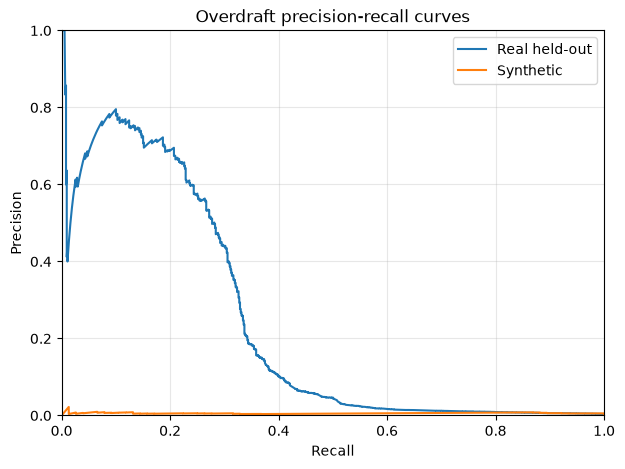

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, y_true, probabilities in [
    ("Real held-out", y_real_test, p_real_test),
    ("Synthetic", y_synthetic, p_synthetic),
]:
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    ax.plot(recall, precision, label=name)
ax.set(title="Overdraft precision-recall curves", xlabel="Recall", ylabel="Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Distribution and relationship diagnostics

Run these after the data-loading and model-evaluation cells. The loader aligns real and synthetic categorical codes; rerun the notebook from the top so the model and scores use the corrected alignment. These plots compare marginal feature drift, feature/label relationships, and the real-trained model's score separation.

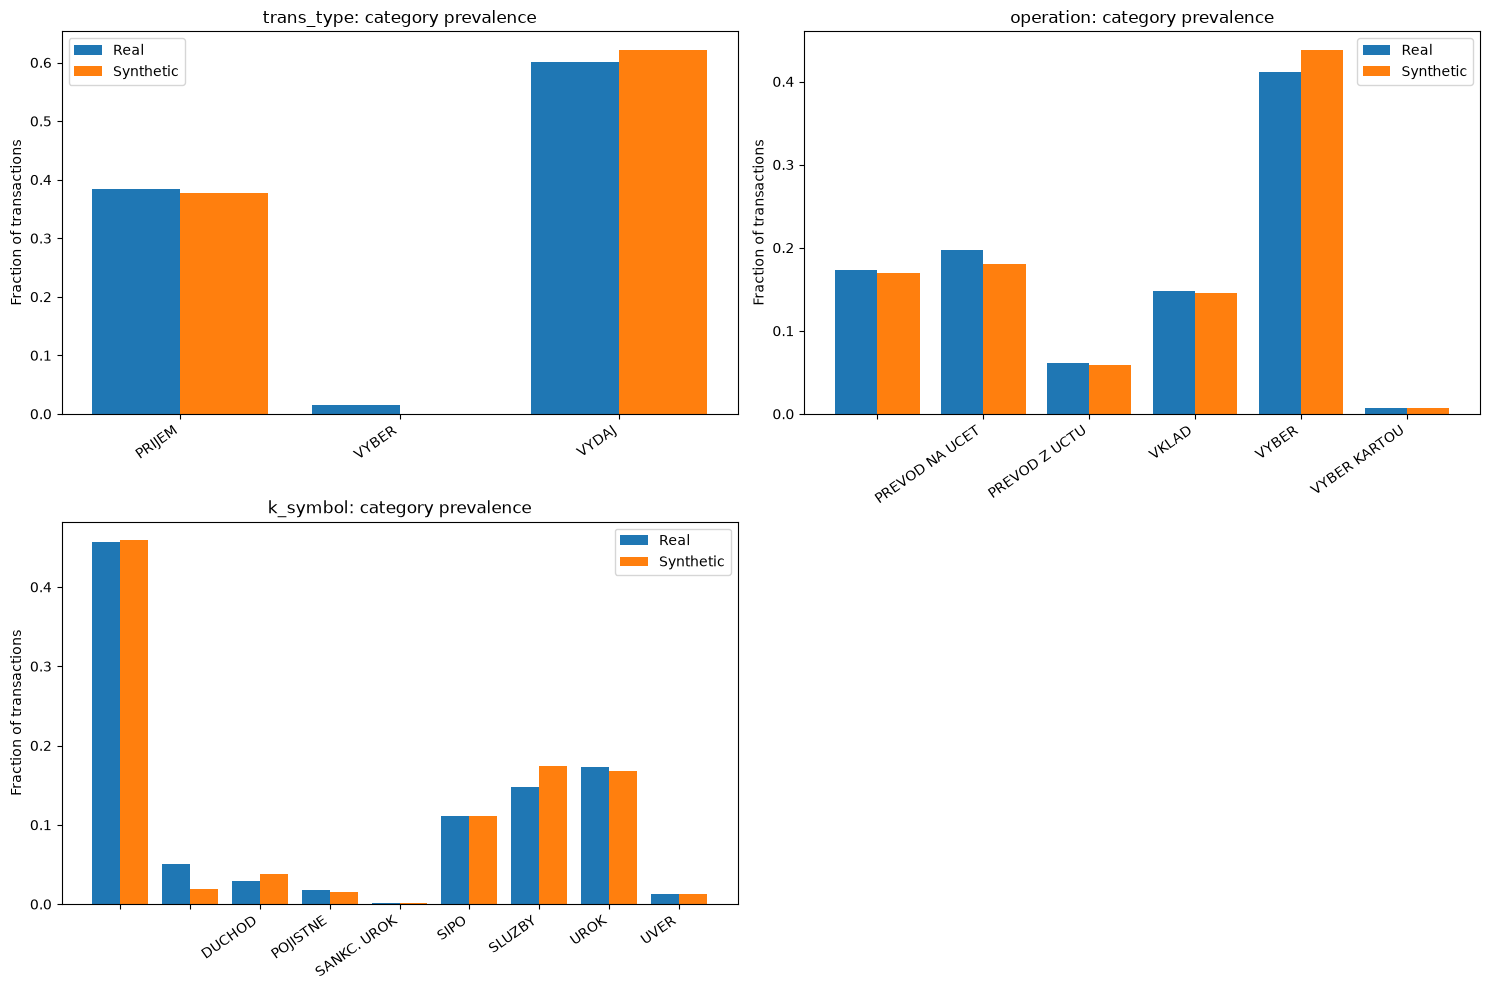

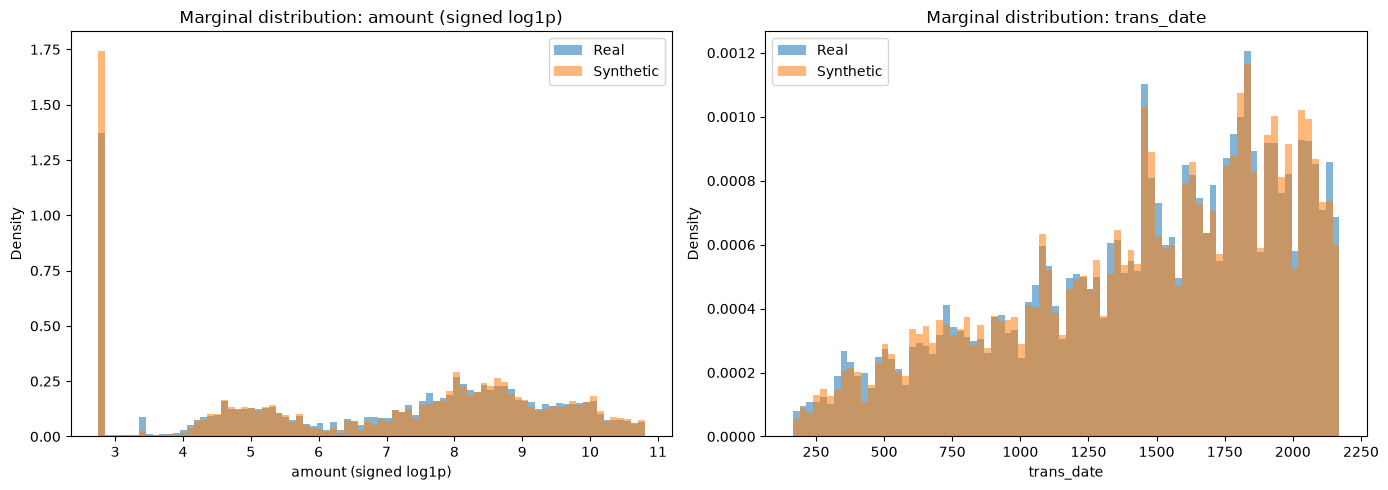

In [6]:
def category_labels_for_plot(data: pd.DataFrame, column: str) -> pd.Series:
    """Map aligned integer category codes to original labels for readable plots."""
    codes = pd.to_numeric(data[column], errors="coerce")
    rounded = codes.round()
    valid = codes.notna() & np.isclose(codes, rounded)
    valid &= rounded.between(0, len(saved_encoders[column].classes_) - 1)
    labels = pd.Series("__unknown__", index=data.index, dtype="object")
    if valid.any():
        labels.loc[valid] = saved_encoders[column].inverse_transform(
            rounded.loc[valid].astype("int64"),
        )
    return labels

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, column in zip(axes.flat, CATEGORICAL_FEATURES, strict=False):
    real_labels = category_labels_for_plot(real, column)
    synthetic_labels = category_labels_for_plot(synthetic, column)
    real_share = real_labels.value_counts(normalize=True)
    synthetic_share = synthetic_labels.value_counts(normalize=True)
    categories = sorted(set(real_share.index) | set(synthetic_share.index))
    x = np.arange(len(categories))
    width = 0.4
    ax.bar(x - width / 2, [real_share.get(c, 0) for c in categories], width, label="Real")
    ax.bar(x + width / 2, [synthetic_share.get(c, 0) for c in categories], width, label="Synthetic")
    ax.set(title=f"{column}: category prevalence", ylabel="Fraction of transactions")
    ax.set_xticks(x, categories, rotation=35, ha="right")
    ax.legend()
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

def signed_log1p(values: pd.Series) -> np.ndarray:
    """Compress long-tailed values while preserving sign."""
    numeric = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    return np.sign(numeric) * np.log1p(np.abs(numeric))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
numeric_plot_data = [("amount (signed log1p)", signed_log1p(real["amount"]), signed_log1p(synthetic["amount"])),
                     ("trans_date", real["trans_date"].to_numpy(), synthetic["trans_date"].to_numpy())]
for ax, (label, real_values, synthetic_values) in zip(axes, numeric_plot_data, strict=False):
    combined = np.concatenate([real_values[np.isfinite(real_values)], synthetic_values[np.isfinite(synthetic_values)]])
    low, high = np.quantile(combined, [0.005, 0.995])
    bins = np.linspace(low, high, 81)
    ax.hist(real_values, bins=bins, density=True, alpha=0.55, label="Real")
    ax.hist(synthetic_values, bins=bins, density=True, alpha=0.55, label="Synthetic")
    ax.set(title=f"Marginal distribution: {label}", xlabel=label, ylabel="Density")
    ax.legend()
fig.tight_layout()
plt.show()

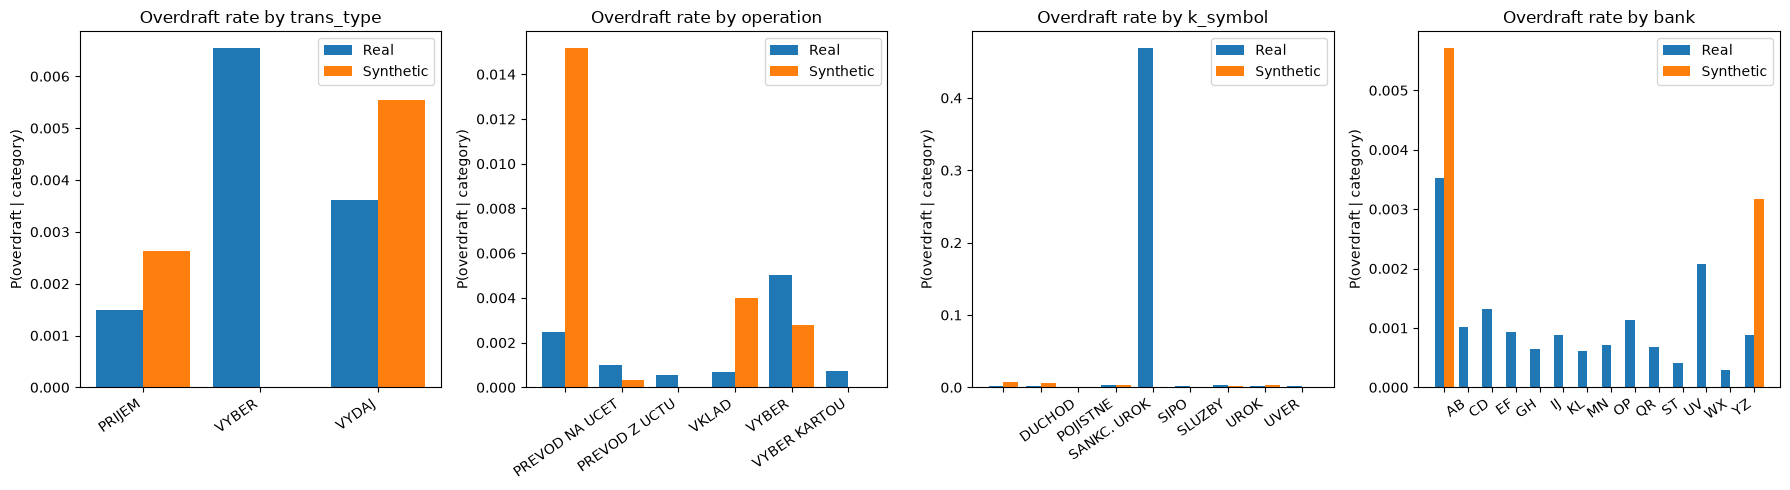

Overdraft rates and support by trans_type:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,PRIJEM,405083,601,0.001484
1,Synthetic,PRIJEM,6462,17,0.002631
2,Real,VYBER,16666,109,0.006540
3,Synthetic,VYBER,1,0,0.000000
4,Real,VYDAJ,634571,2289,0.003607
5,Synthetic,VYDAJ,10643,59,0.005544


Overdraft rates and support by operation:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,183114,456,0.002490
1,Synthetic,,2902,44,0.015162
2,Real,PREVOD NA UCET,208283,208,0.000999
3,Synthetic,PREVOD NA UCET,3083,1,0.000324
4,Real,PREVOD Z UCTU,65226,36,0.000552
5,Synthetic,PREVOD Z UCTU,1011,0,0.000000
6,Real,VKLAD,156743,109,0.000695
7,Synthetic,VKLAD,2491,10,0.004014
8,Real,VYBER,434918,2184,0.005022
9,Synthetic,VYBER,7501,21,0.002800


Overdraft rates and support by k_symbol:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,481881,939,0.001949
1,Synthetic,,7860,56,0.007125
2,Real,,53433,110,0.002059
3,Synthetic,,334,2,0.005988
4,Real,DUCHOD,30338,0,0.000000
5,Synthetic,DUCHOD,657,0,0.000000
6,Real,POJISTNE,18500,54,0.002919
7,Synthetic,POJISTNE,269,1,0.003717
8,Real,SANKC. UROK,1577,739,0.468611
9,Synthetic,SANKC. UROK,25,0,0.000000


Overdraft rates and support by bank:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,782812,2755,0.003519
1,Synthetic,,13139,75,0.005708
2,Real,AB,21720,22,0.001013
3,Synthetic,AB,192,0,0.000000
4,Real,CD,19597,26,0.001327
5,Synthetic,CD,337,0,0.000000
6,Real,EF,21293,20,0.000939
7,Synthetic,EF,393,0,0.000000
8,Real,GH,21499,14,0.000651
9,Synthetic,GH,382,0,0.000000


In [7]:
categorical_rate_tables = {}
fig, axes = plt.subplots(1, len(CATEGORICAL_FEATURES), figsize=(18, 5))
for ax, column in zip(axes, CATEGORICAL_FEATURES, strict=False):
    records = []
    for dataset_name, data in [("Real", real), ("Synthetic", synthetic)]:
        group_data = pd.DataFrame(
            {"category": category_labels_for_plot(data, column), TARGET: data[TARGET]},
        )
        grouped = group_data.groupby("category", observed=True)[TARGET].agg(["size", "sum", "mean"])
        for category, row in grouped.iterrows():
            records.append(
                {
                    "dataset": dataset_name,
                    "category": category,
                    "transactions": int(row["size"]),
                    "overdrafts": int(row["sum"]),
                    "overdraft_rate": float(row["mean"]),
                },
            )
    rates = pd.DataFrame(records)
    categorical_rate_tables[column] = rates
    categories = sorted(rates["category"].unique())
    x = np.arange(len(categories))
    width = 0.4
    for offset, dataset_name in [(-width / 2, "Real"), (width / 2, "Synthetic")]:
        subset = rates[rates["dataset"] == dataset_name].set_index("category")
        ax.bar(
            x + offset,
            [subset["overdraft_rate"].get(category, 0) for category in categories],
            width,
            label=dataset_name,
        )
    ax.set(title=f"Overdraft rate by {column}", ylabel="P(overdraft | category)")
    ax.set_xticks(x, categories, rotation=35, ha="right")
    ax.legend()
fig.tight_layout()
plt.show()

for column, rates in categorical_rate_tables.items():
    print(f"Overdraft rates and support by {column}:")
    display(rates.sort_values(["category", "dataset"]).reset_index(drop=True))

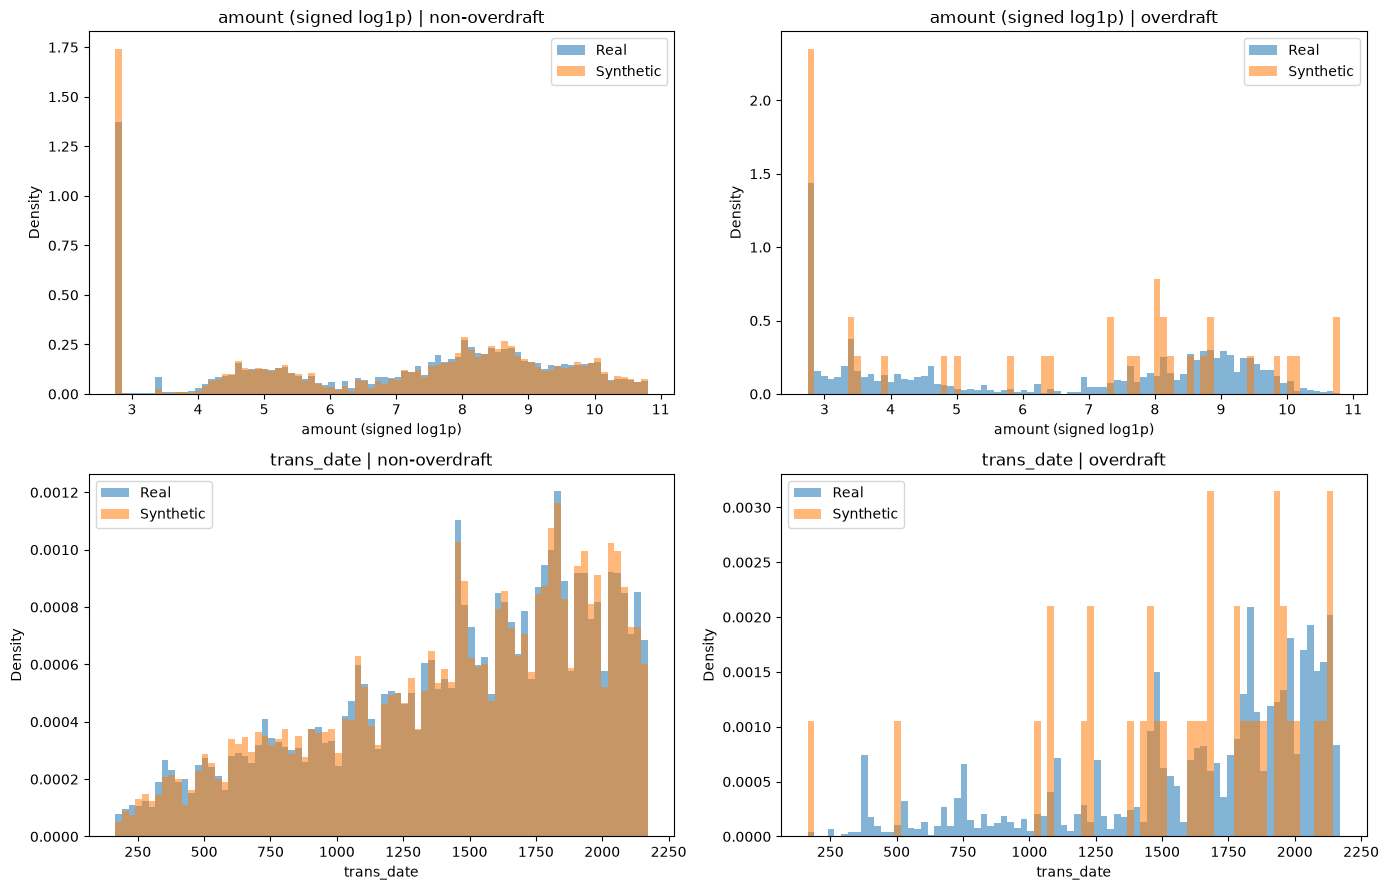

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (feature, transform, label) in enumerate(
    [
        ("amount", signed_log1p, "amount (signed log1p)"),
        ("trans_date", lambda values: pd.to_numeric(values, errors="coerce").to_numpy(dtype=float), "trans_date"),
    ],
):
    class_frames = [
        real.loc[real[TARGET] == 0, feature],
        synthetic.loc[synthetic[TARGET] == 0, feature],
        real.loc[real[TARGET] == 1, feature],
        synthetic.loc[synthetic[TARGET] == 1, feature],
    ]
    transformed = [transform(values) for values in class_frames]
    finite_values = np.concatenate([values[np.isfinite(values)] for values in transformed])
    low, high = np.quantile(finite_values, [0.005, 0.995])
    bins = np.linspace(low, high, 81)
    for col, target_value in enumerate([0, 1]):
        ax = axes[row, col]
        for dataset_name, data in [("Real", real), ("Synthetic", synthetic)]:
            values = transform(data.loc[data[TARGET] == target_value, feature])
            ax.hist(values, bins=bins, density=True, alpha=0.55, label=dataset_name)
        ax.set(
            title=f"{label} | {'overdraft' if target_value else 'non-overdraft'}",
            xlabel=label,
            ylabel="Density",
        )
        ax.legend()
fig.tight_layout()
plt.show()

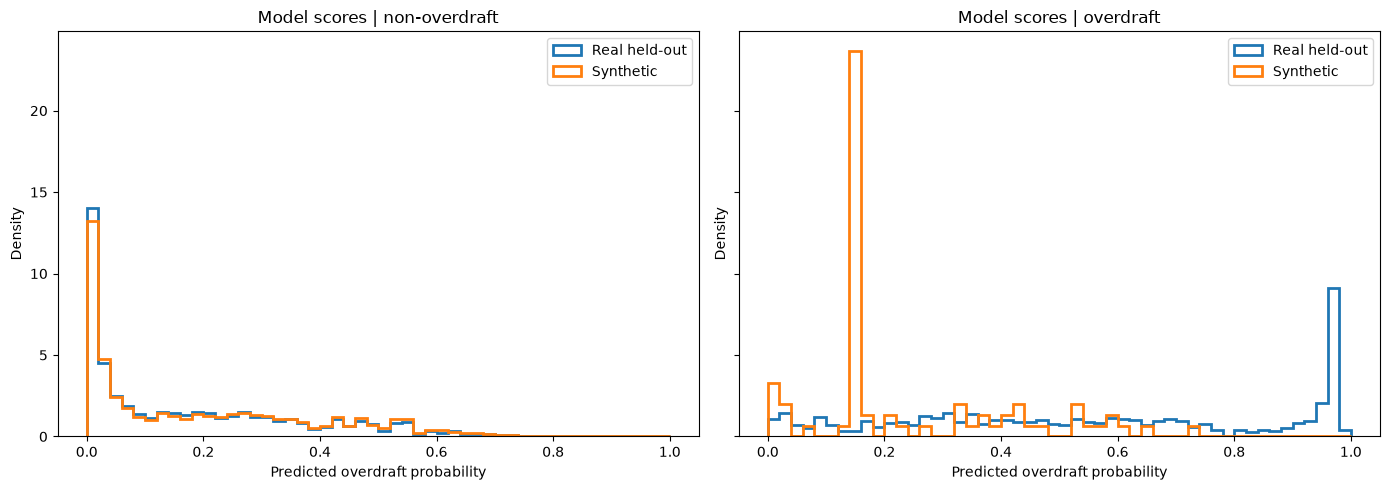

Score separation by dataset and true label:


,dataset,true_label,rows,mean_score,median_score,90th_percentile
0,Real held-out,non-overdraft,210065,0.177271,0.114564,0.467647
1,Real held-out,overdraft,739,0.559007,0.554680,0.972186
2,Synthetic,non-overdraft,17030,0.190721,0.128857,0.496690
3,Synthetic,overdraft,76,0.240362,0.147174,0.533275


In [9]:
real_test_probability = model.predict_proba(real_test[FEATURES])[:, 1]
synthetic_probability = model.predict_proba(synthetic[FEATURES])[:, 1]
score_frames = {
    "Real held-out": (real_test[TARGET].to_numpy(), real_test_probability),
    "Synthetic": (synthetic[TARGET].to_numpy(), synthetic_probability),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
score_bins = np.linspace(0, 1, 51)
for ax, target_value in zip(axes, [0, 1], strict=False):
    for dataset_name, (labels, probabilities) in score_frames.items():
        scores = probabilities[labels == target_value]
        ax.hist(scores, bins=score_bins, density=True, histtype="step", linewidth=2, label=dataset_name)
    ax.set(
        title=f"Model scores | {'overdraft' if target_value else 'non-overdraft'}",
        xlabel="Predicted overdraft probability",
        ylabel="Density",
    )
    ax.legend()
fig.tight_layout()
plt.show()

print("Score separation by dataset and true label:")
score_summary = []
for dataset_name, (labels, probabilities) in score_frames.items():
    for target_value, target_name in [(0, "non-overdraft"), (1, "overdraft")]:
        scores = probabilities[labels == target_value]
        score_summary.append(
            {
                "dataset": dataset_name,
                "true_label": target_name,
                "rows": len(scores),
                "mean_score": float(scores.mean()),
                "median_score": float(np.median(scores)),
                "90th_percentile": float(np.quantile(scores, 0.9)),
            },
        )
display(pd.DataFrame(score_summary))

## Interpretation and limitations

- Compare synthetic average precision and recall with the real account-held-out results; a large gap indicates transfer/domain shift, not necessarily a failure of the real-data model.
- Compare overdraft prevalences first. A synthetic label rate that differs from real data changes precision and average precision even if ranking quality is similar.
- The real and synthetic overdraft labels are both derived from `balance < 0`; `balance` is deliberately absent from `FEATURES`, so the target cannot be trivially read from the predictors.
- Inputs use the transaction table only. The supplied candidate table notes that richer account/client/district context can help, but adding joins and historical aggregates requires leakage-safe temporal feature engineering and aligned synthetic parent-child keys, which this first experiment does not claim to provide.
- This is a baseline experiment. If operational decisions require a different precision/recall trade-off, choose a threshold using a real validation partition, then freeze it before evaluating any test or synthetic set.